# phase 1-4：驗證 EDA 留下的兩個推測

phase 1-3（`01_eda.ipynb`）留下兩個「看起來是這樣、但還沒驗證」的推測：

1. **大安區的總車數半夜一路增加、清晨 5 點最多** —— 是不是調度車半夜在補車？
2. **10/13 那週全區總車數少了約 3 成** —— 原因是什麼？

為什麼值得驗證：如果半夜真的有人在補車，「現在幾台」在清晨會被人為改變，模型要知道這件事；
如果 10/13 那週的少車是全市性的，「全市總車數」就是一個能反映系統狀態的特徵。

資料範圍跟 1-3 一樣：2026-10-01 ~ 10-18。

In [1]:
import warnings

import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
from IPython.display import display

from youbike.data import MODEL_DISTRICTS, available_days, load_snapshots, load_stations

warnings.filterwarnings("ignore", category=DeprecationWarning)
START, END = "2026-10-01", "2026-10-18"

# --- 圖表樣式（跟 01_eda.ipynb 一樣）---
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
C_MAIN, C_HIGHLIGHT, C_REST = "#2a78d6", "#eb6834", "#c3c2b7"
_installed = {f.name for f in font_manager.fontManager.ttflist}
CJK_FONT = next((f for f in ["Microsoft JhengHei", "PingFang TC", "Noto Sans CJK TC"] if f in _installed), "sans-serif")
plt.rcParams.update({
    "font.family": CJK_FONT, "axes.unicode_minus": False, "figure.dpi": 110,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

## 推測 1：半夜是不是調度車在補車？

**怎麼判斷**：一般人還車，同一站 5 分鐘內通常只會多 1 ~ 2 台。
調度車則是一次卸下一整批。所以看「同一站 5 分鐘內一次多 8 台以上」的情況出現在幾點。

要先排除一種假象：有時候某站的資料會瞬間跳上去、下一筆又掉回來（資料傳輸的小錯誤），
那不是真的有車進來。規則是：增加 8 台以上、但下一筆又少了 5 台以上，就當成錯誤不算。

注意：白天熱門的捷運站也常常 5 分鐘就多好幾台（下班時間大家一起還車），
所以「大量增加」本身不等於調度車；要看的是**沒什麼人騎車的凌晨**還有沒有大量增加。

5 分鐘內多 8 台以上：5,239 次，其中 8% 是跳上去又掉回來的錯誤


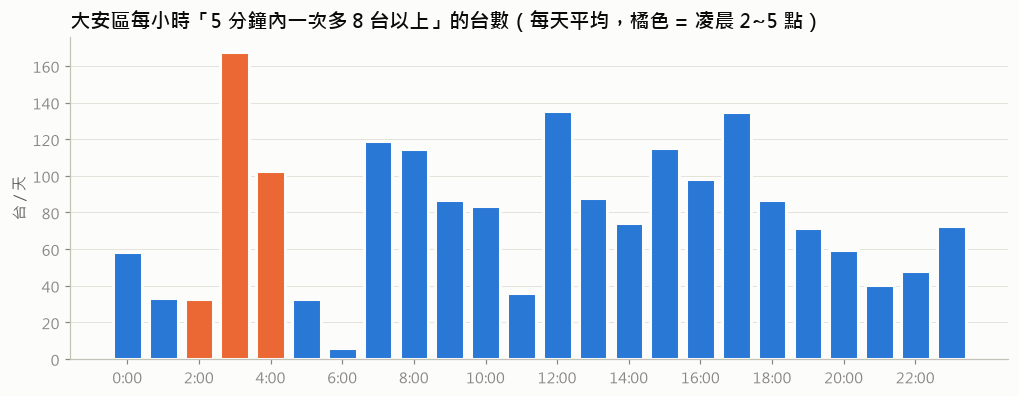

In [2]:
df = load_snapshots(start=START, end=END, district=MODEL_DISTRICTS, with_station_info=True, verbose=False)
df = df.sort_values(["station_id", "src_time"]).reset_index(drop=True)

# 每一筆跟同一站上一筆的差（可借車輛的變化）。中間漏資料（間隔 > 7.5 分鐘）的不算，
# 不然一個空洞前後的差會被誤認成「5 分鐘內大量增加」
gap = df.groupby("station_id")["src_time"].diff().dt.total_seconds() / 60
df["diff"] = df.groupby("station_id")["bikes_available"].diff().where(gap <= 7.5)
df["next_diff"] = df.groupby("station_id")["diff"].shift(-1)

BIG = 8
df["big_jump"] = df["diff"] >= BIG
df["glitch"] = df["big_jump"] & (df["next_diff"] <= -5)       # 跳上去又馬上掉回來
real = df[df["big_jump"] & ~df["glitch"]]
print(f"5 分鐘內多 {BIG} 台以上：{int(df['big_jump'].sum()):,} 次，其中 {df['glitch'].mean() / df['big_jump'].mean():.0%} 是跳上去又掉回來的錯誤")

n_days = df["date"].nunique()
daan = df[df["district"] == "大安區"]
real_daan = real[real["district"] == "大安區"]
by_hour = pd.DataFrame({
    "淨變化": daan.groupby("hour")["diff"].sum() / n_days,
    "大量增加的台數": real_daan.groupby("hour")["diff"].sum() / n_days,
}).fillna(0)

fig, ax = plt.subplots(figsize=(11, 3.8))
colors = [C_HIGHLIGHT if 2 <= h < 5 else C_MAIN for h in by_hour.index]
ax.bar(by_hour.index, by_hour["大量增加的台數"], color=colors, width=0.8, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(0, 24, 2), [f"{h}:00" for h in range(0, 24, 2)])
ax.set_ylabel("台 / 天")
ax.grid(axis="x", visible=False)
ax.set_title(f"大安區每小時「5 分鐘內一次多 {BIG} 台以上」的台數（每天平均，橘色 = 凌晨 2~5 點）")
plt.show()

In [3]:
night = daan[(daan["hour"] >= 2) & (daan["hour"] < 5)]
night_real = real_daan[(real_daan["hour"] >= 2) & (real_daan["hour"] < 5)]
net = night["diff"].sum() / n_days
jump = night_real["diff"].sum() / n_days
print(f"大安區凌晨 2~5 點：每天淨增加約 {net:.0f} 台，其中 {jump:.0f} 台（{jump / net:.0%}）來自一次多 {BIG} 台以上的增加")
print()
print("凌晨 2~5 點大量增加最多的站（18 天合計次數）：")
top = night_real.groupby("name").size().sort_values(ascending=False).head(8)
print(top.rename(index=lambda s: s.replace("YouBike2.0_", "")).to_string())

campus = df[df["district"] == "臺大公館校區"]
print()
c_night = campus[(campus["hour"] >= 2) & (campus["hour"] < 5)]["diff"].sum() / n_days
c_evening = campus[(campus["hour"] >= 16) & (campus["hour"] < 22)]["diff"].sum() / n_days
print(f"對照：臺大公館校區凌晨 2~5 點每天淨增加約 {c_night:.0f} 台；傍晚 16~22 點每天淨減少約 {-c_evening:.0f} 台")

大安區凌晨 2~5 點：每天淨增加約 389 台，其中 302 台（78%）來自一次多 8 台以上的增加

凌晨 2~5 點大量增加最多的站（18 天合計次數）：
name
捷運大安森林公園站(2號出口)    35
捷運信義安和站(4號出口)      32
捷運信義安和站(1號出口)      23
捷運忠孝復興站(1號出口)      17
捷運古亭站(6號出口)        17
龍門廣場               16
捷運公館站(2號出口)        16
捷運忠孝復興站(4號出口)      16

對照：臺大公館校區凌晨 2~5 點每天淨增加約 54 台；傍晚 16~22 點每天淨減少約 626 台


**結論：大致確認，半夜確實有調度車在補車。**

- 大安區凌晨 2 ~ 5 點每天淨增加約 390 台，其中約 8 成來自「一次多 8 台以上、而且沒有掉回去」的增加。
  這個時段幾乎沒有人騎車，一般還車做不到這種量。
- 大量增加集中在**捷運站出口**（大安森林公園、信義安和、忠孝復興、古亭、公館）——
  這很合理：調度把車補到早上通勤一定會用到的地方。
- 臺大校區凌晨也有少量增加（每天約 50 台），但跟傍晚到晚上被騎走的量（每天約 600 台）比起來很少：
  校區晚上空掉的站，大多要等隔天白天有人騎進校園才會回來。

這是從資料推論的結果，YouBike 沒有公開調度紀錄，所以說「大致確認」而不是「確定」。

**對建模的意義**：
- 清晨的「現在幾台」有一部分是被調度車改變的，**凌晨 2 ~ 5 點**的變化不代表騎車需求。
  時段特徵（幾點）能讓模型區分這種情況。
- 早上通勤時捷運站的車，有一部分是半夜補的 —— 如果哪天調度沒來，早上就會特別難借。
  這是模型從現有特徵**看不到**的風險，評估時要知道有這種誤差來源。

## 推測 2：10/13 那週為什麼少了約 3 成的車？

先問一個更基本的問題：**是只有我們的建模範圍少，還是全台北都少？**
如果全市都少，原因就不在大安區本身（例如某幾站壞掉），而是整個系統的狀態。

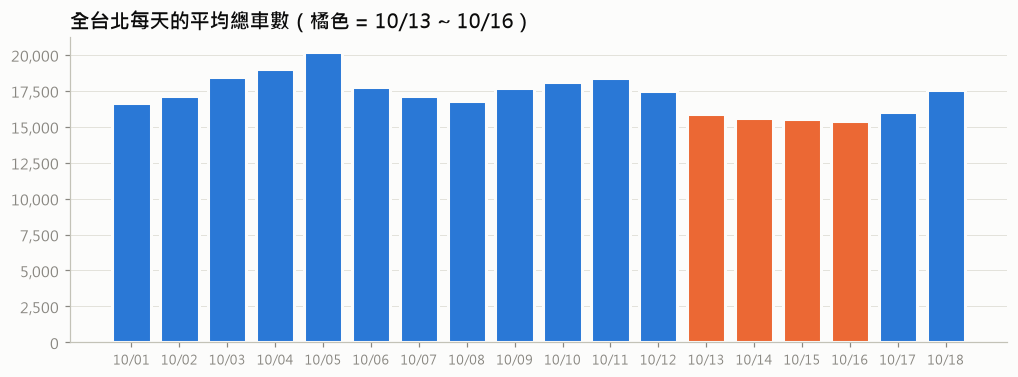

全台北：10/6~8 平均 17,229 台 → 10/13~16 平均 15,613 台（-9.4%）


每天營運中的站數： {'min': 1780, 'max': 1793}


In [4]:
# 讀全台北的資料。只讀需要的四個欄位，記憶體才夠（全市一天約 52 萬列）
st = load_stations()[["station_id", "district"]]
parts = []
for day in available_days():
    if not (START <= day["date"] <= END):
        continue
    for path in day["paths"]:
        t = pq.read_table(path, columns=["station_id", "src_time", "bikes_available", "is_active"])
        t = t.filter(pc.equal(t.column("is_active"), 1)).to_pandas()
        t["date"] = day["date"]
        parts.append(t)
city = pd.concat(parts, ignore_index=True).merge(st, on="station_id", how="left")

# 每個時間點把全市的可借車輛加起來，再取每天平均
city_total = city.groupby(["date", "src_time"])["bikes_available"].sum().groupby("date").mean()
week3 = ["2026-10-13", "2026-10-14", "2026-10-15", "2026-10-16"]
before = ["2026-10-06", "2026-10-07", "2026-10-08"]   # 前一週的上班日（10/9 是補假，不算）

fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [C_HIGHLIGHT if d in week3 else C_MAIN for d in city_total.index]
ax.bar(range(len(city_total)), city_total.values, color=colors, width=0.8, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(len(city_total)), [f"{d[5:7]}/{d[8:]}" for d in city_total.index], fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_title("全台北每天的平均總車數（橘色 = 10/13 ~ 10/16）")
plt.show()

b, w = city_total[before].mean(), city_total[week3].mean()
print(f"全台北：10/6~8 平均 {b:,.0f} 台 → 10/13~16 平均 {w:,.0f} 台（{w / b - 1:+.1%}）")
print("每天營運中的站數：", city.groupby("date")["station_id"].nunique().agg(["min", "max"]).to_dict())

In [5]:
# 各區分開看：哪些區少得最多？有沒有哪一區反而變多（車子流過去）？
by_dist = (city.groupby(["date", "district", "src_time"])["bikes_available"].sum()
               .groupby(["date", "district"]).mean().unstack())
change = pd.DataFrame({
    "10/6~8 平均": by_dist.loc[before].mean().round(0),
    "10/13~16 平均": by_dist.loc[week3].mean().round(0),
})
change["變化"] = change["10/13~16 平均"] / change["10/6~8 平均"] - 1
display(change.sort_values("變化").style.format({"10/6~8 平均": "{:,.0f}", "10/13~16 平均": "{:,.0f}", "變化": "{:+.1%}"}))

,10/6~8 平均,10/13~16 平均,變化
district,,,
臺大公館校區,586,440,-24.9%
內湖區,"2,110","1,690",-19.9%
大安區,"1,997","1,662",-16.8%
松山區,"1,051",901,-14.3%
南港區,"1,254","1,076",-14.2%
信義區,"1,496","1,337",-10.6%
北投區,"1,493","1,344",-10.0%
中山區,"1,779","1,638",-7.9%
中正區,"1,244","1,149",-7.6%


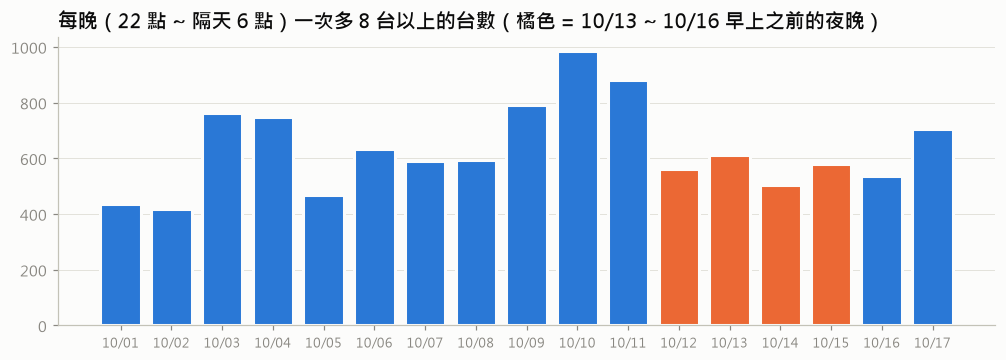

10/6~8 早上之前的夜晚平均 563 台；10/13~16 早上之前的夜晚平均 564 台（+0%）


In [6]:
# 半夜的調度量有沒有變少？（每晚 22 點 ~ 隔天 6 點，建模範圍裡「一次多 8 台以上」的台數）
night_mask = (real["hour"] >= 22) | (real["hour"] < 6)
# 22~23 點算到「隔天早上」那一晚：時間往前推 6 小時再取日期
night_of = (real.loc[night_mask, "time_taipei"] - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")
per_night = real.loc[night_mask].groupby(night_of)["diff"].sum()
per_night = per_night[(per_night.index >= START) & (per_night.index < END)]   # 只留完整的夜晚

fig, ax = plt.subplots(figsize=(11, 3.4))
colors = [C_HIGHLIGHT if d in ["2026-10-12"] + week3[:-1] else C_MAIN for d in per_night.index]
ax.bar(range(len(per_night)), per_night.values, color=colors, width=0.8, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(len(per_night)), [f"{d[5:7]}/{d[8:]}" for d in per_night.index], fontsize=8.5)
ax.grid(axis="x", visible=False)
ax.set_title("每晚（22 點 ~ 隔天 6 點）一次多 8 台以上的台數（橘色 = 10/13 ~ 10/16 早上之前的夜晚）")
plt.show()

# 比較時要對齊：「10/12 的夜晚」補的是 10/13 早上的車，所以
#   10/6~8 早上之前的夜晚 = 10/5、10/6、10/7
#   10/13~16 早上之前的夜晚 = 10/12、10/13、10/14、10/15
n_before = per_night[["2026-10-05", "2026-10-06", "2026-10-07"]].mean()
n_week3 = per_night[["2026-10-12", "2026-10-13", "2026-10-14", "2026-10-15"]].mean()
print(f"10/6~8 早上之前的夜晚平均 {n_before:.0f} 台；10/13~16 早上之前的夜晚平均 {n_week3:.0f} 台（{n_week3 / n_before - 1:+.0%}）")

**結論：原因找不到，但範圍縮小了。**

- **不是大安區自己的問題**：全台北的總車數也一起下降（約 −9%），大部分的區都變少；
  大安區（約 −17%）和臺大校區（約 −25%）掉得比全市平均多，只有萬華、大同反而變多。
- **可以排除的原因**：
  - 站點沒有減少（每天營運中的站數穩定在約 1,790 站）；
  - 半夜的調度量沒有變少（那幾晚平均約 565 台，跟前一週的對應夜晚幾乎一樣）。
    圖上週末前後的夜晚比較高，是因為週末白天車子被騎散，晚上要補的比較多。
- **剩下的可能**是全市層級的因素：那幾天在路上被騎的車比較多、或比較多車被收去維修。
  光從「站上有幾台」的資料分辨不出來（我們看不到路上和維修中的車）。

**對建模的意義**：
- 「**全市現在總共有多少可借車**」可以當特徵 —— 它能反映這種整個系統的狀態，
  而且我們本來就收集全市的資料（收集範圍 ≠ 建模範圍的好處）。
- 這種漂移再次說明：評估要看不只一段測試期。

## 1-4 總結

| 推測 | 結果 | 對 phase 3 的影響 |
|---|---|---|
| 半夜有調度車在補車 | **大致確認**：凌晨 2~5 點大安區每天淨增加約 390 台，約 8 成是一次多 8 台以上的增加，集中在捷運站出口 | 時段特徵能區分凌晨的人為變化；「調度沒來」是模型看不到的誤差來源 |
| 10/13 那週少車的原因 | **找不到原因，但確定是全市性的**（全市 −9%，排除站點減少、調度變少） | 新增「全市總可借車數」特徵；評估看不只一段測試期 |